In [1]:
#Weighted K means cluster with random forest fit on climatology to determine weights
import os
import numpy as np
import geopandas as gpd
import rasterio
import rioxarray as rxr
import xarray as xr
from sklearn.preprocessing import StandardScaler
from rasterio.stack import stack
import matplotlib.pyplot as plt

In [ ]:
# Load Climatological Layers (20-year aggregates of all variables) into a stacked raster

temp_file_path = r"..\Data\Processed\Spatial_clustering\Temp"
file_list = [f for f in os.listdir(temp_file_path) if f.endswith(".tif")]
data_arrays = {}

#we use one sample raster to reproject_match all other rasters to the exact same grid
sample_raster = rxr.open_rasterio(r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_max.tif")

for file in file_list:
    
    #read variable(band) name
    var_name = file.split(".")[0]
    da = rxr.open_rasterio(os.path.join(temp_file_path, file), masked=True)

    #reproject to match sample raster
    da = da.rio.reproject_match(sample_raster)

    #remove band dimension (for single band rasters)
    if da.shape[0] == 1:
        da = da.squeeze('band', drop = True)
    
    data_arrays[var_name] = da
        
#print(data_arrays.keys())
stacked_ds = xr.Dataset(data_arrays)



<xarray.Dataset> Size: 60MB
Dimensions:                                      (x: 983, y: 493)
Coordinates:
  * x                                            (x) float64 8kB 79.66 ... 88.48
  * y                                            (y) float64 4kB 30.6 ... 26.18
    spatial_ref                                  int64 8B 0
Data variables: (12/20)
    DEM_1km_aspect_mean                          (y, x) float32 2MB nan ... nan
    DEM_1km_elevation_max                        (y, x) float32 2MB nan ... nan
    DEM_1km_elevation_mean                       (y, x) float64 4MB nan ... nan
    DEM_1km_elevation_min                        (y, x) float32 2MB nan ... nan
    DEM_1km_elevation_std                        (y, x) float64 4MB nan ... nan
    DEM_1km_slope_mean                           (y, x) float32 2MB nan ... nan
    ...                                           ...
    fetch_dist_500m_resampled                    (y, x) float32 2MB nan ... nan
    MODIS_2_evi_clim_resampled                   (y, x) float64 4MB nan ... nan
    MODIS_2_lst_diff_clim_resampled              (y, x) float64 4MB 4.215 ......
    MODIS_2_lst_d_clim_resampled                 (y, x) float64 4MB 188.5 ......
    MODIS_2_lst_n_clim_resampled                 (y, x) float64 4MB 188.0 ......
    prec_clim_resampled                          (y, x) float32 2MB 637.4 ......

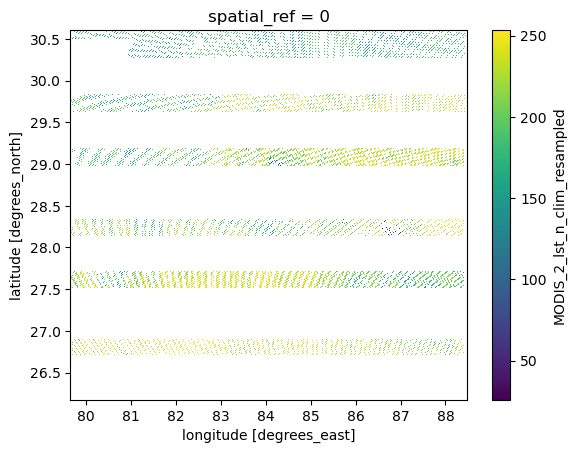

In [28]:
#check a few rasters by visualizing
stacked_ds.MODIS_2_lst_n_clim_resampled.plot()
plt.show()
